# Threshold curve in the $(p, p_{\mathrm{bell},z})$ plane — Bell models & equivalents

Headline figure: every fitted threshold is a 2D point $(p^*, p_{\mathrm{bell},z}^*)$
on the noise plane. Each noise model is drawn as a separate curve.

- **bias scan**: direction $\beta = p_{\mathrm{bell},z}/p$, threshold lands at
  $(p^*, \beta \cdot p^*)$.
- **fixed-$p_{\mathrm{bell},z}$ scan**: $p_{\mathrm{bell},z}$ held constant,
  threshold lands at $(p^*, p_{\mathrm{bell},z}^{\mathrm{fixed}})$.

`biased_bell_v2` / `biased_bell_v3` fits come pre-computed from
`threshold_comparison_bell.ipynb` (`out/collection/threshold_bell_fits.csv`).
The single-ancilla equivalents — `biased_bell_v3_equivalent` and
`biased_bell_v3_equivalent_majority` — are fitted in-place from their raw decode
CSVs (`out/collection/threshold_equivalent,*.csv` and
`threshold_equivalent_majority,*.csv`, written by `tools/equivalent/run_decode*.sh`).
Each equivalent should land on top of `biased_bell_v3`; the majority variant
trades extra rounds for a lower effective measurement error.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / 'src'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%load_ext autoreload
%autoreload 2

In [2]:
fits_path = Path('../out/collection/threshold_bell_fits.csv')
if not fits_path.exists():
    raise FileNotFoundError(
        f'No fits at {fits_path}. Run threshold_comparison_bell.ipynb first.'
    )

fits_df = pd.read_csv(fits_path)

# Backwards-compat: older fits CSVs lacked the noise_model column.
if 'noise_model' not in fits_df.columns:
    fits_df['noise_model'] = 'biased_bell_v2'

print('fits per noise_model:')
print(fits_df.groupby('noise_model').size())
fits_df

fits per noise_model:
noise_model
biased_bell_v2    12
biased_bell_v3    11
dtype: int64


,noise_model,direction,direction_kind,bias,p_bell_z_fixed,p_th,p_th_err,mu,mu_err,p_init,n_points
0,biased_bell_v2,bias=0,bias,0.0,NaN,0.002418,2.159251e-05,0.910499,0.044097,0.002512,15
1,biased_bell_v2,bias=1,bias,1.0,NaN,0.002047,1.233021e-05,0.971927,0.035426,0.002154,14
2,biased_bell_v2,bias=2,bias,2.0,NaN,0.001701,2.051408e-05,0.756509,0.026000,0.001585,13
3,biased_bell_v2,bias=3,bias,3.0,NaN,0.001486,9.182376e-06,0.954573,0.026916,0.001585,14
4,biased_bell_v2,bias=5,bias,5.0,NaN,0.001196,1.259919e-05,0.815859,0.025822,0.001166,13
5,biased_bell_v2,bias=10,bias,10.0,NaN,0.000795,4.923095e-06,0.880964,0.021115,0.000858,14
6,biased_bell_v2,bias=20,bias,20.0,NaN,0.000492,6.146875e-06,0.713299,0.025259,0.000464,13
7,biased_bell_v2,bias=30,bias,30.0,NaN,0.000348,2.581181e-06,0.791440,0.017868,0.000341,13
8,biased_bell_v2,bias=50,bias,50.0,NaN,0.000220,1.991365e-06,0.884524,0.030904,0.000251,12
9,biased_bell_v2,bias=100,bias,100.0,NaN,0.000116,8.823396e-07,0.963759,0.036348,0.000136,9


In [3]:
# Append the equivalent models. Unlike v2/v3 (pre-fitted in
# threshold_comparison_bell.ipynb), the equivalent results are raw decode CSVs
# from tools/equivalent/run_decode*.sh, so we fit them here with the same
# locate -> quadratic-FSS pipeline, then concat onto fits_df. Both the
# single-ancilla equivalent and its majority-vote variant are loaded; each
# CSV's metadata carries the right noise_model, so they separate automatically.
import ast
import glob

from threshold_fit import locate_threshold, fit_threshold

# Glob(s) for raw equivalent decode CSVs. Add more here for new variants.
EQUIV_CSV_GLOBS = [
    '../out/collection/threshold_equivalent,*.csv',
    '../out/collection/threshold_equivalent_majority,*.csv',
]
# Equivalent model names this cell owns (stale rows are dropped before append).
EQUIV_MODELS = [
    'biased_bell_v3_equivalent',
    'biased_bell_v3_equivalent_majority',
]
N_PER_SIDE = 2          # 5-point window around p_init
LOGICAL_CUTOFF = 0.45   # drop saturated points

equiv_files = sorted(f for g in EQUIV_CSV_GLOBS for f in glob.glob(g))
if not equiv_files:
    print(f'No equivalent CSVs matched {EQUIV_CSV_GLOBS}; skipping.')
else:
    print(f'Loading {len(equiv_files)} equivalent CSV(s):')
    for f in equiv_files:
        print(f'  {f}')

    edf = pd.concat([pd.read_csv(f) for f in equiv_files], ignore_index=True)
    # Merge repeated runs by strong_id (same circuit + decoder).
    edf = edf.groupby('strong_id').agg({
        'shots': 'sum', 'errors': 'sum', 'discards': 'sum', 'seconds': 'sum',
        'decoder': 'first', 'json_metadata': 'first',
    }).reset_index()

    meta = edf['json_metadata'].apply(
        lambda m: ast.literal_eval(m) if isinstance(m, str) else dict(m)
    )
    for col in [
        'p', 'p_bell_z', 'direction_kind', 'direction_value',
        'bias', 'p_bell_z_fixed', 'expected_distance', 'rounds', 'k',
        'noise_model',
    ]:
        edf[col] = meta.apply(lambda m, c=col: m.get(c))

    def _direction_label(row):
        if row['direction_kind'] == 'bias':
            b = row['direction_value']
            return f'bias={int(b) if b == int(b) else b:g}'
        return f'pbz={row["direction_value"]:.4g}'

    edf['direction'] = edf.apply(_direction_label, axis=1)

    equiv_fit_rows = []
    for (noise_model, direction_name), grp in edf.groupby(['noise_model', 'direction']):
        p_arr = grp['p'].to_numpy(dtype=float)
        d_arr = grp['expected_distance'].to_numpy(dtype=float)
        rounds_arr = grp['rounds'].to_numpy(dtype=float)
        k_arr = grp['k'].to_numpy(dtype=float)
        shots_arr = grp['shots'].to_numpy(dtype=float)
        errors_arr = grp['errors'].to_numpy(dtype=float)

        valid = (
            (shots_arr > 0) & (errors_arr > 0)
            & (errors_arr < shots_arr * LOGICAL_CUTOFF)
        )
        pL_total = np.where(valid, errors_arr / np.maximum(shots_arr, 1), np.nan)
        sigma_total = np.where(
            valid,
            np.sqrt(
                np.clip(pL_total * (1 - pL_total), 0, None)
                / np.maximum(shots_arr, 1)
            ),
            np.nan,
        )
        scale = d_arr / (rounds_arr * np.maximum(k_arr, 1))
        pL = 1 - (1 - pL_total) ** scale
        sigma = sigma_total * scale * (1 - pL_total) ** (scale - 1)

        p_init = locate_threshold(p_arr, d_arr, pL)
        if p_init is None:
            continue
        try:
            fit = fit_threshold(
                p_arr, d_arr, pL, sigma=sigma, p_init=p_init,
                n_per_side=N_PER_SIDE,
            )
        except Exception as exc:
            print(f'[skip] {noise_model} / {direction_name}: {exc}')
            continue
        if fit is None:
            continue

        equiv_fit_rows.append({
            'noise_model': noise_model,
            'direction': direction_name,
            'direction_kind': grp['direction_kind'].iloc[0],
            'bias': grp['bias'].iloc[0],
            'p_bell_z_fixed': grp['p_bell_z_fixed'].iloc[0],
            'p_th': fit.p_th,
            'p_th_err': fit.p_th_err,
            'mu': fit.mu,
            'mu_err': fit.mu_err,
            'p_init': fit.p_init,
            'n_points': fit.n_points,
        })

    equiv_fits_df = pd.DataFrame(equiv_fit_rows)
    # Drop any stale equivalent rows, then append the freshly-fitted ones.
    fits_df = fits_df[~fits_df['noise_model'].isin(EQUIV_MODELS)]
    fits_df = pd.concat([fits_df, equiv_fits_df], ignore_index=True)

    print(f'\nFitted {len(equiv_fits_df)} equivalent-model directions.')
    print('fits per noise_model (after append):')
    print(fits_df.groupby('noise_model').size())

equiv_fits_df if equiv_files else fits_df

Loading 2 equivalent CSV(s):
  ../out/collection/threshold_equivalent,2026-06-28.csv
  ../out/collection/threshold_equivalent_majority,2026-06-28.csv



Fitted 22 equivalent-model directions.
fits per noise_model (after append):
noise_model
biased_bell_v2                        12
biased_bell_v3                        11
biased_bell_v3_equivalent             11
biased_bell_v3_equivalent_majority    11
dtype: int64


,noise_model,direction,direction_kind,bias,p_bell_z_fixed,p_th,p_th_err,mu,mu_err,p_init,n_points
0,biased_bell_v3_equivalent,bias=1,bias,1.0,NaN,0.002047,1.804862e-05,0.908614,0.026532,0.002154,14
1,biased_bell_v3_equivalent,bias=10,bias,10.0,NaN,0.000792,6.445446e-06,0.906777,0.025451,0.000858,14
2,biased_bell_v3_equivalent,bias=100,bias,100.0,NaN,0.000113,9.887457e-07,0.989753,0.031982,0.000136,11
3,biased_bell_v3_equivalent,bias=2,bias,2.0,NaN,0.001732,1.783448e-05,0.766935,0.022284,0.001585,15
4,biased_bell_v3_equivalent,bias=20,bias,20.0,NaN,0.000482,5.370969e-06,0.766993,0.025356,0.000464,14
5,biased_bell_v3_equivalent,bias=3,bias,3.0,NaN,0.001575,1.521958e-05,0.771676,0.022808,0.001585,15
6,biased_bell_v3_equivalent,bias=30,bias,30.0,NaN,0.000341,2.916417e-06,0.801614,0.021118,0.000341,15
7,biased_bell_v3_equivalent,bias=5,bias,5.0,NaN,0.001202,1.112608e-05,0.808810,0.022342,0.001166,15
8,biased_bell_v3_equivalent,bias=50,bias,50.0,NaN,0.000218,1.679113e-06,0.951888,0.026200,0.000251,14
9,biased_bell_v3_equivalent,pbz=0.001,pbz,NaN,0.001,0.002290,2.211094e-05,0.815532,0.022960,0.002154,15


In [4]:
NOISE_MODEL_COLORS = {
    'biased_bell_v2': '#e15759',  # red-ish
    'biased_bell_v3': '#4e79a7',  # blue-ish
    'biased_bell_v3_equivalent': '#59a14f',  # green-ish
    'biased_bell_v3_equivalent_majority': '#b07aa1',  # purple-ish
}
NOISE_MODELS_PRESENT = sorted(
    fits_df['noise_model'].unique(),
    key=lambda m: list(NOISE_MODEL_COLORS).index(m) if m in NOISE_MODEL_COLORS else 99,
)

bias_by_model = {
    m: fits_df[(fits_df['noise_model'] == m) & (fits_df['direction_kind'] == 'bias')]
        .sort_values('bias').reset_index(drop=True)
    for m in NOISE_MODELS_PRESENT
}
pbz_by_model = {
    m: fits_df[(fits_df['noise_model'] == m) & (fits_df['direction_kind'] == 'pbz')]
        .sort_values('p_bell_z_fixed').reset_index(drop=True)
    for m in NOISE_MODELS_PRESENT
}
for m in NOISE_MODELS_PRESENT:
    print(f'{m}: {len(bias_by_model[m])} bias points, '
          f'{len(pbz_by_model[m])} fixed-pbz points')

biased_bell_v2: 10 bias points, 2 fixed-pbz points
biased_bell_v3: 9 bias points, 2 fixed-pbz points
biased_bell_v3_equivalent: 9 bias points, 2 fixed-pbz points
biased_bell_v3_equivalent_majority: 9 bias points, 2 fixed-pbz points


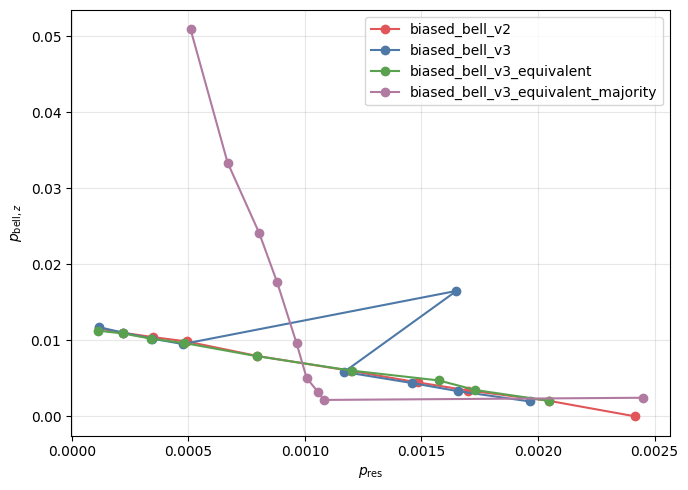

In [5]:
# Each fitted threshold -> point (p_th, beta * p_th) on the (p, p_bell_z) plane.
# One curve per noise model. v3, its single-ancilla equivalent, and the
# majority-vote variant should fall on top of each other (equivalence check).
fig, ax = plt.subplots(figsize=(7, 5))

PLOT_MODELS = [m for m in [
    'biased_bell_v2', 'biased_bell_v3',
    'biased_bell_v3_equivalent', 'biased_bell_v3_equivalent_majority',
] if m in NOISE_MODELS_PRESENT]
for model in PLOT_MODELS:
    bdf = bias_by_model[model]
    if bdf.empty:
        continue
    p = bdf['p_th'].to_numpy(dtype=float)
    pbz = bdf['bias'].to_numpy(dtype=float) * p
    ax.plot(p, pbz, 'o-', color=NOISE_MODEL_COLORS.get(model, 'k'),
            label=model)

ax.set_xlabel(r'$p_\text{res}$')
ax.set_ylabel(r'$p_{\mathrm{bell},z}$')
# ax.set_title(r'Threshold points $(p^*, \beta p^*)$')
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()
plt.savefig('../out/figures/threshold_bell_curves.pdf', bbox_inches='tight')
plt.show()

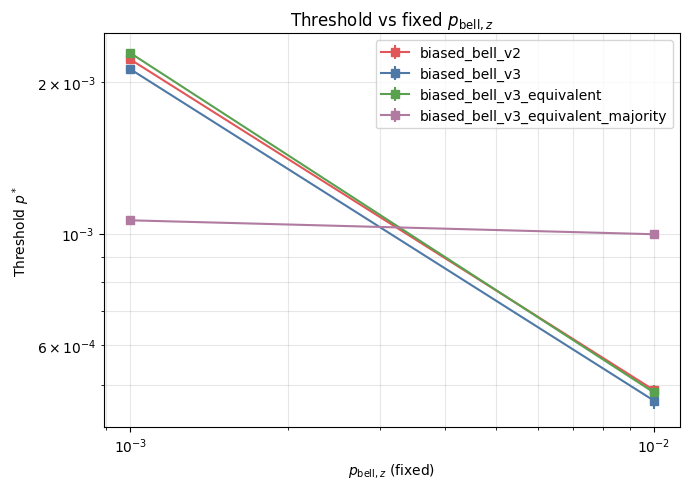

In [6]:
# p_th vs fixed p_bell_z (independent scan, easier to interpret
# experimentally because p_bell_z is set by hardware). One curve per noise model.
fig, ax = plt.subplots(figsize=(7, 5))
plotted = False
for model in NOISE_MODELS_PRESENT:
    pdf = pbz_by_model[model]
    if pdf.empty:
        continue
    plotted = True
    ax.errorbar(
        pdf['p_bell_z_fixed'], pdf['p_th'], yerr=pdf['p_th_err'],
        fmt='s-', color=NOISE_MODEL_COLORS.get(model, 'k'),
        label=f'{model}',
    )
if plotted:
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlabel(r'$p_{\mathrm{bell},z}$ (fixed)')
    ax.set_ylabel(r'Threshold $p^*$')
    ax.set_title(r'Threshold vs fixed $p_{\mathrm{bell},z}$')
    ax.grid(True, alpha=0.3, which='both')
    ax.legend()
    fig.tight_layout()
    plt.show()
else:
    print('No fixed-pbz fits to plot.')

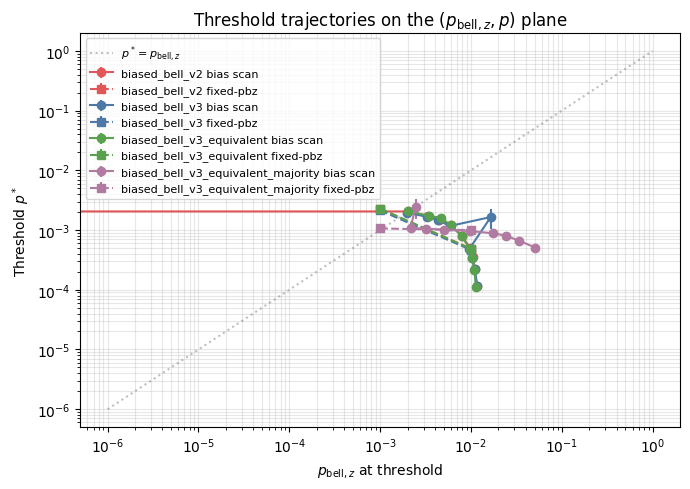

In [7]:
# Combined view: both scans on one (p_bell_z, p_th) plane, one set of curves
# per noise model.
# - bias scan: each point is (p_th * beta, p_th).
# - fixed-pbz scan: each point is (p_bell_z_fixed, p_th).
fig, ax = plt.subplots(figsize=(7, 5))

for model in NOISE_MODELS_PRESENT:
    color = NOISE_MODEL_COLORS.get(model, 'k')
    bdf = bias_by_model[model]
    if not bdf.empty:
        bx = bdf['bias'] * bdf['p_th']
        ax.errorbar(
            bx, bdf['p_th'], yerr=bdf['p_th_err'],
            fmt='o-', color=color, label=f'{model} bias scan',
        )
    pdf = pbz_by_model[model]
    if not pdf.empty:
        ax.errorbar(
            pdf['p_bell_z_fixed'], pdf['p_th'], yerr=pdf['p_th_err'],
            fmt='s--', color=color, label=f'{model} fixed-pbz',
        )

ax.plot(
    [1e-6, 1.0], [1e-6, 1.0],
    color='gray', linestyle=':', alpha=0.5, label=r'$p^* = p_{\mathrm{bell},z}$',
)

ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel(r'$p_{\mathrm{bell},z}$ at threshold')
ax.set_ylabel(r'Threshold $p^*$')
ax.set_title(r'Threshold trajectories on the $(p_{\mathrm{bell},z}, p)$ plane')
ax.grid(True, alpha=0.3, which='both')
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()